In [1]:
pip install tabulate

Note: you may need to restart the kernel to use updated packages.


In [ ]:
# Imports and Setup 
import warnings
warnings.filterwarnings('ignore')

import os
import shutil
import random
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yaml
import cv2
from PIL import Image
from collections import Counter
from ultralytics import YOLO
import torch

print("CUDA available:", torch.cuda.is_available())
print("CUDA device count:", torch.cuda.device_count())

CUDA available: True
CUDA device count: 1


In [ ]:
#  Paths and Dataset Split 
base_dir = 'Surgical-Dataset'
dataset_path = 'surgical_yolo_dataset'
images_all = os.path.join(base_dir, "Images/All/images")
labels_dir = os.path.join(base_dir, "Labels/label object names")
train_txt = os.path.join(base_dir, "Test-TrainGroups/train-obj_detector.txt")
val_txt = os.path.join(base_dir, "Test-TrainGroups/test-obj_detector.txt")

for split in ['images/train', 'images/val', 'labels/train', 'labels/val']:
    os.makedirs(os.path.join(dataset_path, split), exist_ok=True)

def copy_split(txt_file, image_dst, label_dst):
    with open(txt_file, 'r') as f:
        lines = f.read().splitlines()
    copied = 0
    for line in lines:
        filename = os.path.basename(line.strip())
        labelname = filename.replace('.jpg', '.txt')
        src_img = os.path.join(images_all, filename)
        src_lbl = os.path.join(labels_dir, labelname)
        if os.path.exists(src_img) and os.path.exists(src_lbl):
            shutil.copy(src_img, image_dst)
            shutil.copy(src_lbl, label_dst)
            copied += 1
    print(f"✅ Copied {copied} items from {txt_file}")

copy_split(train_txt, os.path.join(dataset_path, 'images/train'), os.path.join(dataset_path, 'labels/train'))
copy_split(val_txt, os.path.join(dataset_path, 'images/val'), os.path.join(dataset_path, 'labels/val'))

✅ Copied 1834 items from Surgical-Dataset\Test-TrainGroups/train-obj_detector.txt
✅ Copied 786 items from Surgical-Dataset\Test-TrainGroups/test-obj_detector.txt


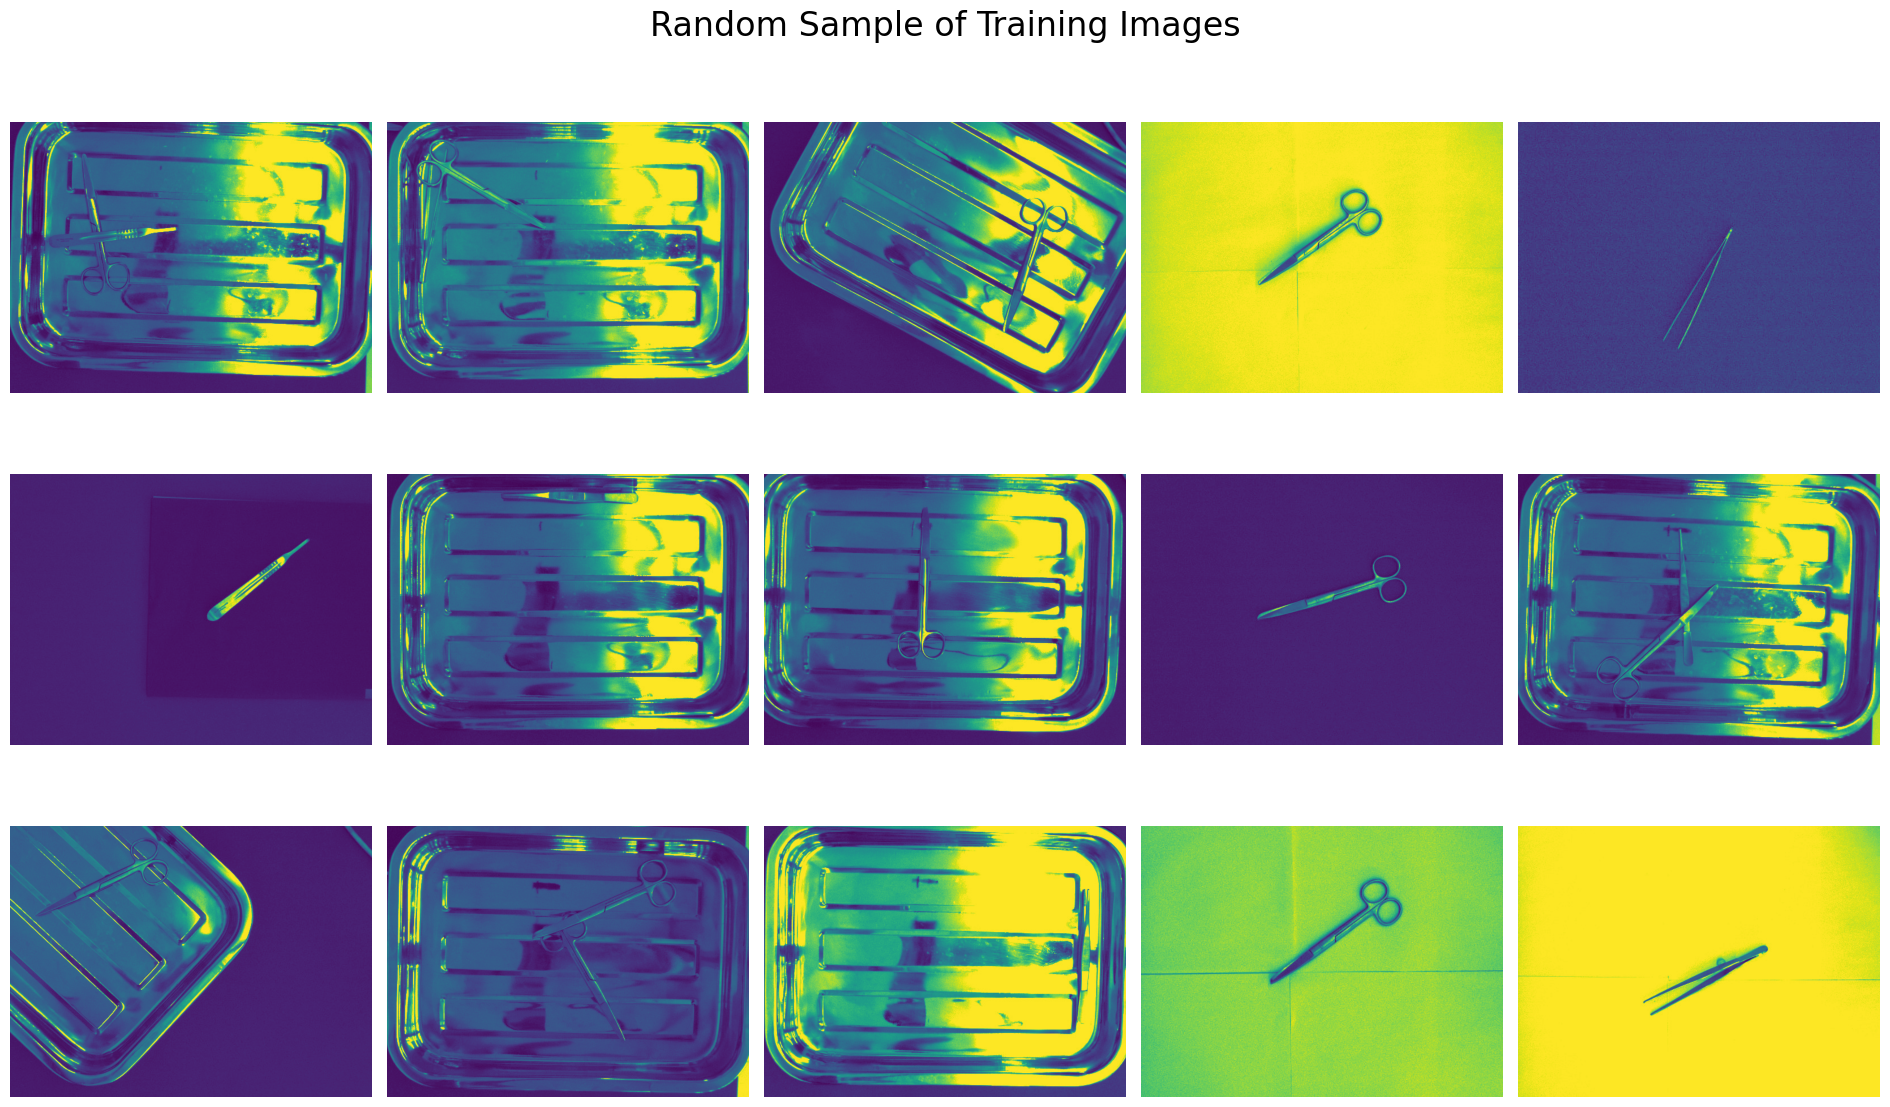

In [ ]:

# Random Training Images 
train_images_path = os.path.join(dataset_path, 'images/train')
image_files = [f for f in os.listdir(train_images_path) if f.endswith('.jpg')]
random.seed(0)
random_images = random.sample(image_files, 15)

plt.figure(figsize=(19, 12))
for i, image_file in enumerate(random_images):
    image_path = os.path.join(train_images_path, image_file)
    image = Image.open(image_path)
    plt.subplot(3, 5, i + 1)
    plt.imshow(image)
    plt.axis('off')
plt.suptitle('Random Sample of Training Images', fontsize=24)
plt.tight_layout()
plt.show()

In [ ]:
#  YOLO Data Config 
data_yaml = {
    'path': dataset_path,
    'train': 'images/train',
    'val': 'images/val',
    'names': [
        'Scalpel',
        'Straight Dissection Clamp',
        'Straight Mayo Scissor',
        'Curved Mayo Scissor'
    ]
}
with open('data.yaml', 'w') as f:
    yaml.dump(data_yaml, f)

#  Train YOLOv8n, v8m, v9c 
model_variants = {
    "YOLOv8n": "yolov8n.pt",
    "YOLOv8m": "yolov8m.pt",
    "YOLOv9c": "yolov9c.pt"
}

for name, weights in model_variants.items():
    print(f"\n🚀 Training {name}...")
    model = YOLO(weights)
    model.train(
        data='data.yaml',
        epochs=100,
        imgsz=640,
        batch=16,
        name=f'{name}_model',
        device=0
    )


🚀 Training YOLOv8n...
New https://pypi.org/project/ultralytics/8.3.170 available  Update with 'pip install -U ultralytics'
Ultralytics 8.3.168  Python-3.12.7 torch-2.5.1+cu121 CUDA:0 (NVIDIA GeForce RTX 4080, 16376MiB)
engine\trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=False, name=YOLOv8n_model3, nbs=64, nms=False, op

train: Scanning C:\Users\james\Downloads\ProjectDL2\Project\surgical_yolo_dataset\labels\train.cache... 1834 images, 0 


val: Fast image access  (ping: 0.10.0 ms, read: 8.03.8 MB/s, size: 59.2 KB)


val: Scanning C:\Users\james\Downloads\ProjectDL2\Project\surgical_yolo_dataset\labels\val.cache... 786 images, 0 backg


Plotting labels to runs\detect\YOLOv8n_model3\labels.jpg... 
optimizer: 'optimizer=auto' found, ignoring 'lr0=0.01' and 'momentum=0.937' and determining best 'optimizer', 'lr0' and 'momentum' automatically... 
optimizer: AdamW(lr=0.00125, momentum=0.9) with parameter groups 57 weight(decay=0.0), 64 weight(decay=0.0005), 63 bias(decay=0.0)
Image sizes 640 train, 640 val
Using 8 dataloader workers
Logging results to runs\detect\YOLOv8n_model3
Starting training for 100 epochs...

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size


      1/100         2G      1.116      2.756      1.251         28        640: 100%|██████████| 115/115 [00:09<00:00, 1
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 25/25 [00:02


... (901 outputs left out)

                   all        786       1092       0.98      0.976      0.994      0.952



100 epochs completed in 0.934 hours.
Optimizer stripped from runs\detect\YOLOv9c_model\weights\last.pt, 51.6MB
Optimizer stripped from runs\detect\YOLOv9c_model\weights\best.pt, 51.6MB

Validating runs\detect\YOLOv9c_model\weights\best.pt...
Ultralytics 8.3.168  Python-3.12.7 torch-2.5.1+cu121 CUDA:0 (NVIDIA GeForce RTX 4080, 16376MiB)
YOLOv9c summary (fused): 156 layers, 25,322,332 parameters, 0 gradients, 102.3 GFLOPs


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 25/25 [00:04


                   all        786       1092      0.977      0.979      0.993      0.954
               Scalpel        273        273      0.985      0.967      0.994      0.934
Straight Dissection Clamp        273        273      0.937      0.982      0.992      0.918
 Straight Mayo Scissor        272        272          1      0.973      0.994      0.982
   Curved Mayo Scissor        274        274      0.985      0.992      0.994      0.984
Speed: 0.1ms preprocess, 2.9ms inference, 0.0ms loss, 0.7ms postprocess per image
Results saved to runs\detect\YOLOv9c_model


In [ ]:
# Load Best Models 
best_models = {name: YOLO(f"runs/detect/{name}_model/weights/best.pt") for name in model_variants}

#  Select Validation Images 
val_images_path = os.path.join(dataset_path, 'images/val')
image_files = [f for f in os.listdir(val_images_path) if f.endswith('.jpg')]
selected_images = [image_files[i] for i in range(0, len(image_files), max(1, len(image_files)//9))][:9]

#  Run Inference and Collect Detections 
detection_summary = {}

for model_name, model in best_models.items():
    detection_summary[model_name] = {}
    for image_name in selected_images:
        image_path = os.path.join(val_images_path, image_name)
        result = model.predict(source=image_path, imgsz=640)[0]
        class_ids = result.boxes.cls.tolist() if result.boxes else []
        label_names = [result.names[int(cls)] for cls in class_ids]
        detection_summary[model_name][image_name] = label_names if label_names else ["No Detection"]



image 1/1 C:\Users\james\Downloads\ProjectDL2\Project\surgical_yolo_dataset\images\val\bisturi1.jpg: 480x640 1 Scalpel, 25.1ms
Speed: 0.7ms preprocess, 25.1ms inference, 2.6ms postprocess per image at shape (1, 3, 480, 640)

image 1/1 C:\Users\james\Downloads\ProjectDL2\Project\surgical_yolo_dataset\images\val\bisturi401.jpg: 480x640 1 Scalpel, 5.0ms
Speed: 0.6ms preprocess, 5.0ms inference, 1.1ms postprocess per image at shape (1, 3, 480, 640)

image 1/1 C:\Users\james\Downloads\ProjectDL2\Project\surgical_yolo_dataset\images\val\bisturi716.jpg: 480x640 1 Scalpel, 1 Curved Mayo Scissor, 5.3ms
Speed: 0.6ms preprocess, 5.3ms inference, 1.2ms postprocess per image at shape (1, 3, 480, 640)

image 1/1 C:\Users\james\Downloads\ProjectDL2\Project\surgical_yolo_dataset\images\val\pinca320.jpg: 480x640 1 Straight Dissection Clamp, 5.0ms
Speed: 0.5ms preprocess, 5.0ms inference, 1.3ms postprocess per image at shape (1, 3, 480, 640)

image 1/1 C:\Users\james\Downloads\ProjectDL2\Project\surgic

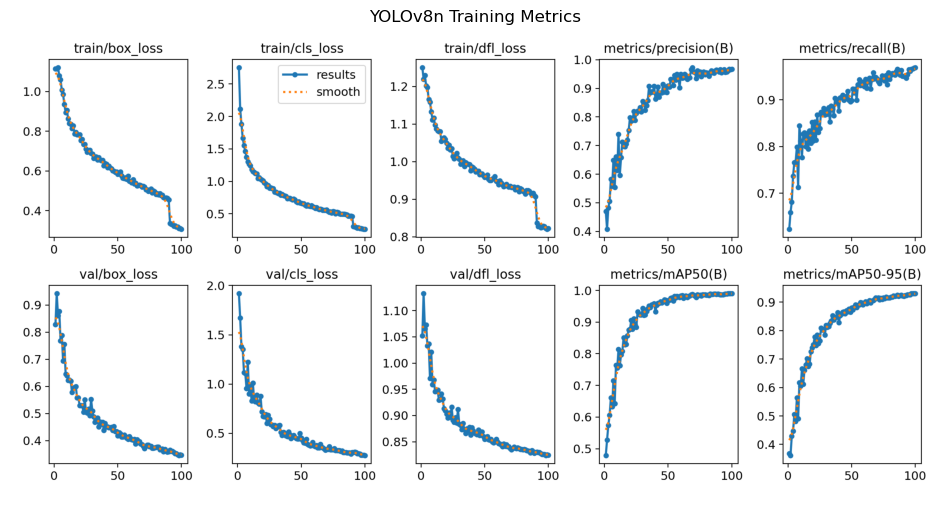

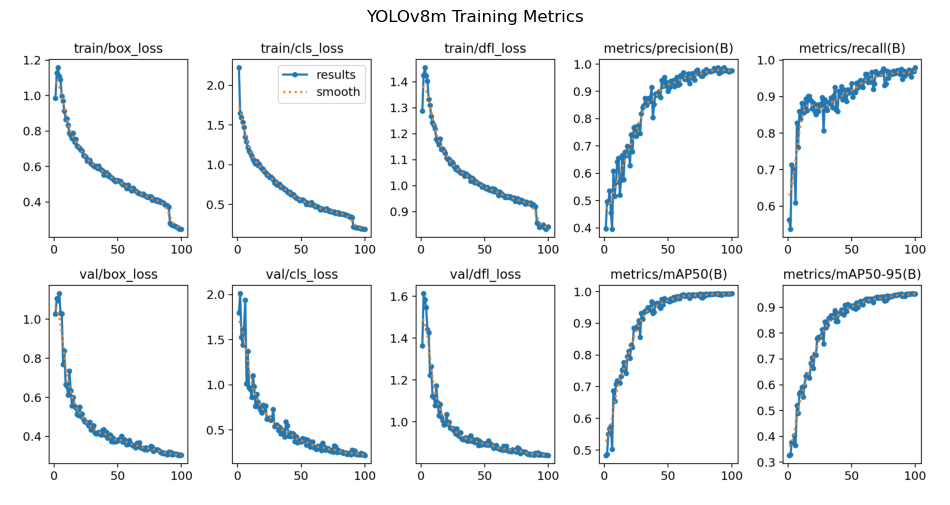

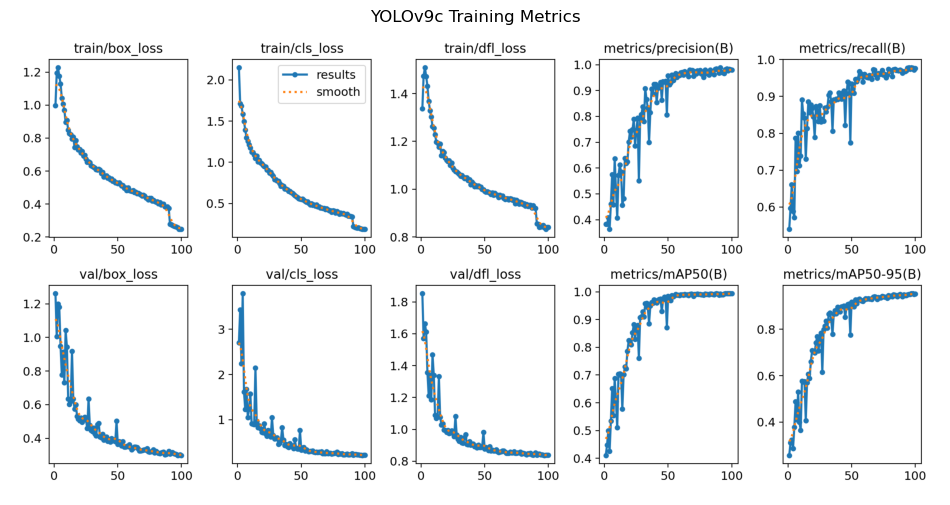

In [ ]:
# Plot Training Metrics 
for model_name in model_variants:
    results_img = f"runs/detect/{model_name}_model/results.png"
    if os.path.exists(results_img):
        img = Image.open(results_img)
        plt.figure(figsize=(12, 8))
        plt.imshow(img)
        plt.axis('off')
        plt.title(f'{model_name} Training Metrics')
        plt.show()

In [ ]:
#  Evaluate YOLO Models 
print("\n📈 Model Evaluation Metrics:\n")
metrics_all = {}

for name, model in best_models.items():
    metrics = model.val()
    metrics_all[name] = {
        "mAP50": round(metrics.box.map50, 4),
        "mAP50-95": round(metrics.box.map, 4),
        "Precision": round(metrics.box.mp, 4),
        "Recall": round(metrics.box.mr, 4)

    }

metrics_df = pd.DataFrame(metrics_all).T
print(metrics_df)


📈 Model Evaluation Metrics:

Ultralytics 8.3.168  Python-3.12.7 torch-2.5.1+cu121 CUDA:0 (NVIDIA GeForce RTX 4080, 16376MiB)
val: Fast image access  (ping: 0.00.0 ms, read: 761.7346.3 MB/s, size: 62.4 KB)


val: Scanning C:\Users\james\Downloads\ProjectDL2\Project\surgical_yolo_dataset\labels\val.cache... 786 images, 0 backg
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 50/50 [00:02


                   all        786       1092      0.966      0.968       0.99      0.931
               Scalpel        273        273      0.989      0.958      0.993      0.895
Straight Dissection Clamp        273        273      0.954      0.967      0.988      0.889
 Straight Mayo Scissor        272        272      0.969      0.956      0.989      0.964
   Curved Mayo Scissor        274        274      0.951      0.993       0.99      0.975
Speed: 0.2ms preprocess, 0.7ms inference, 0.0ms loss, 0.7ms postprocess per image
Results saved to runs\detect\val
Ultralytics 8.3.168  Python-3.12.7 torch-2.5.1+cu121 CUDA:0 (NVIDIA GeForce RTX 4080, 16376MiB)
val: Fast image access  (ping: 0.00.0 ms, read: 752.1267.4 MB/s, size: 56.5 KB)


val: Scanning C:\Users\james\Downloads\ProjectDL2\Project\surgical_yolo_dataset\labels\val.cache... 786 images, 0 backg
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 50/50 [00:04


                   all        786       1092      0.972      0.972      0.993      0.953
               Scalpel        273        273      0.996      0.963      0.994      0.929
Straight Dissection Clamp        273        273      0.967       0.98      0.992      0.922
 Straight Mayo Scissor        272        272      0.989      0.948      0.993      0.981
   Curved Mayo Scissor        274        274      0.937      0.996      0.993      0.981
Speed: 0.1ms preprocess, 3.5ms inference, 0.0ms loss, 0.6ms postprocess per image
Results saved to runs\detect\val2
Ultralytics 8.3.168  Python-3.12.7 torch-2.5.1+cu121 CUDA:0 (NVIDIA GeForce RTX 4080, 16376MiB)
val: Fast image access  (ping: 0.00.0 ms, read: 560.9231.7 MB/s, size: 55.0 KB)


val: Scanning C:\Users\james\Downloads\ProjectDL2\Project\surgical_yolo_dataset\labels\val.cache... 786 images, 0 backg
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 50/50 [00:05


                   all        786       1092      0.977      0.979      0.993      0.954
               Scalpel        273        273      0.985      0.967      0.994      0.933
Straight Dissection Clamp        273        273      0.937      0.983      0.991      0.916
 Straight Mayo Scissor        272        272          1      0.973      0.994      0.982
   Curved Mayo Scissor        274        274      0.985      0.992      0.994      0.983
Speed: 0.2ms preprocess, 4.6ms inference, 0.0ms loss, 0.6ms postprocess per image
Results saved to runs\detect\val3
          mAP50  mAP50-95  Precision  Recall
YOLOv8n  0.9901    0.9306     0.9657  0.9685
YOLOv8m  0.9931    0.9531     0.9721  0.9719
YOLOv9c  0.9935    0.9538     0.9769  0.9786


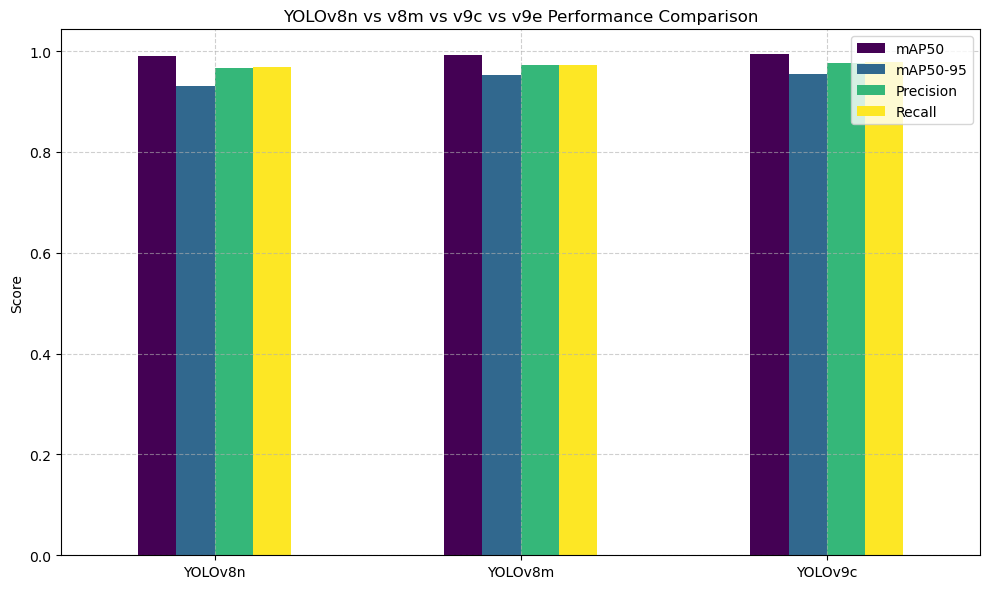

In [25]:
metrics_df.plot(kind='bar', figsize=(10, 6), colormap='viridis')
plt.title("YOLOv8n vs v8m vs v9c vs v9e Performance Comparison")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
# Save Results 
metrics_df.to_csv("yolo_model_comparison.csv")
print("\n📁 Saved model comparison metrics to yolo_model_comparison.csv") 


📁 Saved model comparison metrics to yolo_model_comparison.csv


In [29]:
from tabulate import tabulate

print("\n📊 YOLO Model Comparison (Tabular Format):\n")
print(tabulate(metrics_df.reset_index().rename(columns={'index': 'Model'}), headers='keys', tablefmt='pretty'))


📊 YOLO Model Comparison (Tabular Format):

+---+---------+--------+----------+-----------+--------+
|   |  Model  | mAP50  | mAP50-95 | Precision | Recall |
+---+---------+--------+----------+-----------+--------+
| 0 | YOLOv8n | 0.9901 |  0.9306  |  0.9657   | 0.9685 |
| 1 | YOLOv8m | 0.9931 |  0.9531  |  0.9721   | 0.9719 |
| 2 | YOLOv9c | 0.9935 |  0.9538  |  0.9769   | 0.9786 |
+---+---------+--------+----------+-----------+--------+
